# Notebook 03 — Learning Behaviour and Error Analysis

**Project:** Brain Tumor MRI Classification  
**Model:** ResNet50 transfer learning + fine-tuning  
**Purpose:** Diagnose the baseline model's generalization behaviour without training another model.

This notebook loads the best model saved by Notebook 02. It does not fit or fine-tune any layers.

## Questions this notebook investigates
1. How did training and validation performance change across epochs?
2. Which classes are most frequently misclassified?
3. Are there high-confidence incorrect predictions?
4. Are errors associated with simple image properties such as dimensions, brightness, or border brightness?
5. Which individual images should be inspected next?

**Important:** The test set is used here for post-training error analysis. Do not use these results to tune the model and then report the same test set as an untouched final evaluation. Any changes decided from this analysis should be evaluated on a new independent test set if one becomes available.

## Cell 1 — Import libraries

In [1]:
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from pathlib import Path
from PIL import Image

from tensorflow import keras
from tensorflow.keras.applications.resnet50 import preprocess_input

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report
)
from sklearn.calibration import calibration_curve

print("TensorFlow:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPU devices: []


## Cell 2 — Configure paths

Run this notebook from the same project working directory used for Notebook 02. If your working directory is different, update `PROJECT_DIR`.

Expected files from Notebook 02:
- `outputs/notebook_02/models/resnet50_baseline_best.keras`
- `outputs/notebook_02/results/training_history.csv`

In [2]:
# Change this if your Notebook 02 outputs are stored elsewhere.
PROJECT_DIR = Path.cwd()

DATASET_DIR = Path(r"E:\SEM5\ERA\ERA_Project\Brain_Tumor\data")
TEST_DIR = DATASET_DIR / "Testing"

NOTEBOOK_02_DIR = PROJECT_DIR / "outputs" / "notebook_02"
MODEL_PATH = NOTEBOOK_02_DIR / "models" / "resnet50_baseline_best.keras"
HISTORY_PATH = NOTEBOOK_02_DIR / "results" / "training_history.csv"

OUTPUT_DIR = PROJECT_DIR / "outputs" / "notebook_03"
RESULTS_DIR = OUTPUT_DIR / "results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

CLASS_NAMES = ["glioma", "meningioma", "notumor", "pituitary"]
IMAGE_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42

print("Project directory:", PROJECT_DIR)
print("Model:", MODEL_PATH)
print("Test directory:", TEST_DIR)
print("Notebook 02 history:", HISTORY_PATH)

assert MODEL_PATH.exists(), f"Model not found: {MODEL_PATH}"
assert TEST_DIR.exists(), f"Test directory not found: {TEST_DIR}"

Project directory: e:\SEM5\ERA\ERA_Project\Brain_Tumor
Model: e:\SEM5\ERA\ERA_Project\Brain_Tumor\outputs\notebook_02\models\resnet50_baseline_best.keras
Test directory: E:\SEM5\ERA\ERA_Project\Brain_Tumor\data\Testing
Notebook 02 history: e:\SEM5\ERA\ERA_Project\Brain_Tumor\outputs\notebook_02\results\training_history.csv


## Cell 3 — Load the saved model

The model is loaded for inference only. No training operation is performed in this notebook.

In [3]:
model = keras.models.load_model(MODEL_PATH, compile=False)
print("Saved ResNet50 model loaded.")
model.summary()

Saved ResNet50 model loaded.


Model: "ResNet50_Baseline"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 2048)           │         8,192 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       524,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │         1,028 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 24,121,476 (92.02 MB)

 Trainable params: 14,958,340 (57.06 MB)

 Non-trainable params: 9,163,136 (34.95 MB)

## Cell 4 — Load the test dataset

The class order must match Notebook 02 exactly. We use `shuffle=False` so predictions, labels, and file paths remain aligned.

In [4]:
test_ds_raw = tf.keras.utils.image_dataset_from_directory(
    TEST_DIR,
    labels="inferred",
    label_mode="int",
    class_names=CLASS_NAMES,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)

AUTOTUNE = tf.data.AUTOTUNE

def preprocess_evaluation(image, label):
    image = tf.cast(image, tf.float32)
    image = preprocess_input(image)
    return image, label

test_ds = (
    test_ds_raw
    .map(preprocess_evaluation, num_parallel_calls=AUTOTUNE)
    .prefetch(AUTOTUNE)
)

test_file_paths = list(test_ds_raw.file_paths)
print("Test files:", len(test_file_paths))
print("Class order:", test_ds_raw.class_names)

Found 1600 files belonging to 4 classes.
Test files: 1600
Class order: ['glioma', 'meningioma', 'notumor', 'pituitary']


## Cell 5 — Load the learning history from Notebook 02

This plots the actual training and validation history recorded during the two training phases. If the CSV is missing, this cell reports that rather than inventing history.

In [5]:
if HISTORY_PATH.exists():
    history_df = pd.read_csv(HISTORY_PATH)
    print(history_df.tail())
else:
    history_df = None
    print("Training history CSV not found. Check HISTORY_PATH.")

    accuracy      loss  val_accuracy  val_loss  learning_rate
12  0.976562  0.064481      0.999107  0.007467       0.000010
13  0.986384  0.042859      0.998214  0.010017       0.000010
14  0.986384  0.039351      0.998214  0.008599       0.000010
15  0.989509  0.032510      0.998214  0.009365       0.000002
16  0.990179  0.030699      0.998214  0.009596       0.000002


## Cell 6 — Plot accuracy and loss curves

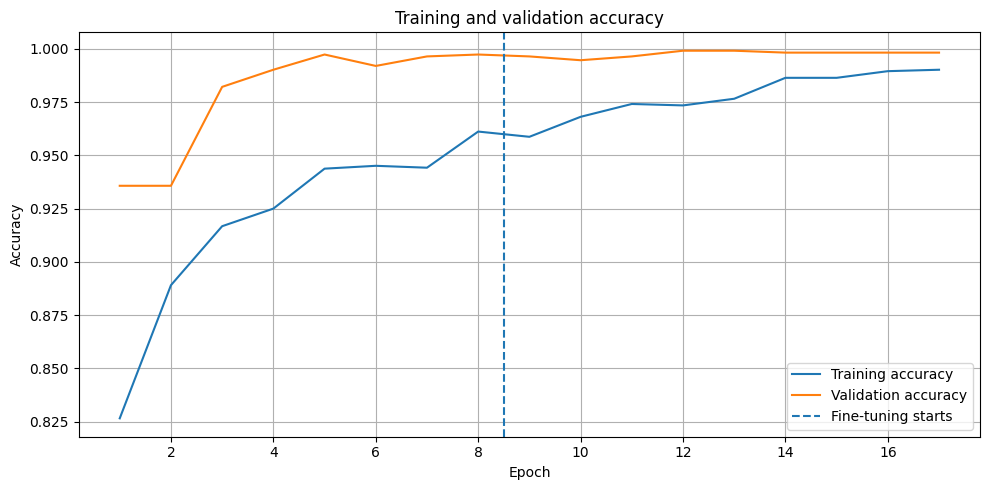

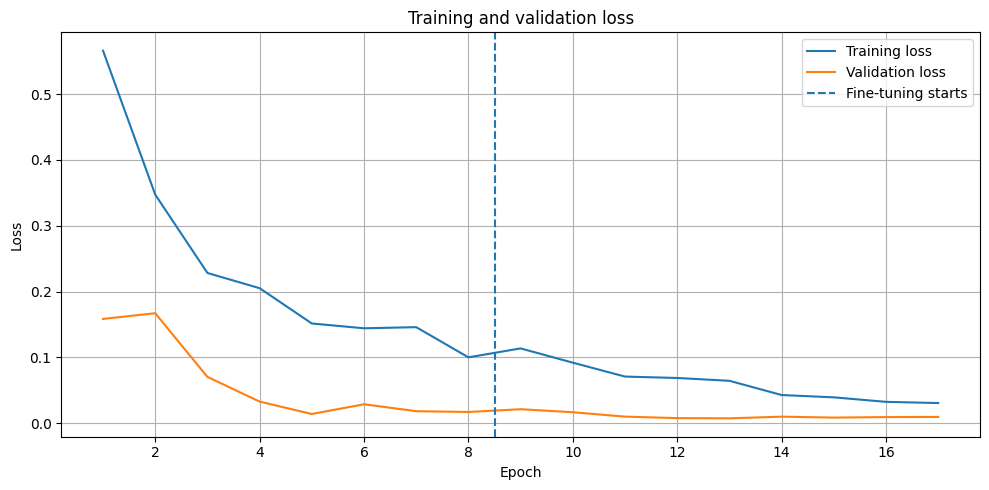

In [6]:
if history_df is not None:
    epochs = np.arange(1, len(history_df) + 1)

    plt.figure(figsize=(10, 5))
    plt.plot(epochs, history_df["accuracy"], label="Training accuracy")
    plt.plot(epochs, history_df["val_accuracy"], label="Validation accuracy")
    plt.axvline(x=8.5, linestyle="--", label="Fine-tuning starts")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.title("Training and validation accuracy")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.savefig(RESULTS_DIR / "accuracy_curve.png", dpi=300)
    plt.show()

    plt.figure(figsize=(10, 5))
    plt.plot(epochs, history_df["loss"], label="Training loss")
    plt.plot(epochs, history_df["val_loss"], label="Validation loss")
    plt.axvline(x=8.5, linestyle="--", label="Fine-tuning starts")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.title("Training and validation loss")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.savefig(RESULTS_DIR / "loss_curve.png", dpi=300)
    plt.show()
else:
    print("Skipping learning curves because training_history.csv is unavailable.")

## Cell 7 — Generate test predictions

This reproduces the baseline test evaluation using the saved model. The test set is not used for gradient updates.

In [7]:
y_true = np.concatenate([labels.numpy() for _, labels in test_ds])
y_prob = model.predict(test_ds, verbose=1)
y_pred = np.argmax(y_prob, axis=1)
confidence = np.max(y_prob, axis=1)
correct = (y_true == y_pred)

assert len(y_true) == len(y_pred) == len(test_file_paths)

print("Test accuracy:", round(accuracy_score(y_true, y_pred), 4))
print("Macro precision:", round(precision_score(y_true, y_pred, average="macro", zero_division=0), 4))
print("Macro recall:", round(recall_score(y_true, y_pred, average="macro", zero_division=0), 4))
print("Macro F1:", round(f1_score(y_true, y_pred, average="macro", zero_division=0), 4))

50/50 ━━━━━━━━━━━━━━━━━━━━ 54s 1s/step
Test accuracy: 0.9119
Macro precision: 0.9134
Macro recall: 0.9119
Macro F1: 0.91


## Cell 8 — Per-class classification report and confusion matrix

              precision    recall  f1-score   support

      glioma       0.94      0.78      0.85       400
  meningioma       0.85      0.88      0.87       400
     notumor       0.96      1.00      0.98       400
   pituitary       0.90      0.99      0.94       400

    accuracy                           0.91      1600
   macro avg       0.91      0.91      0.91      1600
weighted avg       0.91      0.91      0.91      1600



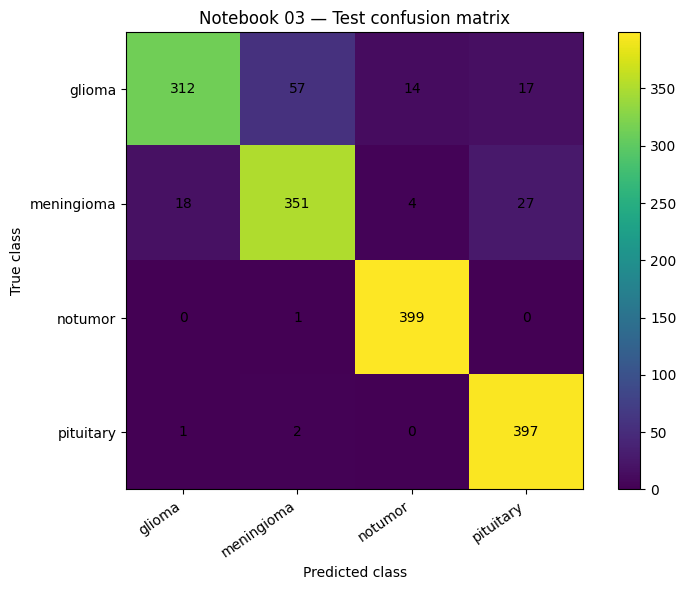

In [8]:
report_text = classification_report(
    y_true, y_pred, target_names=CLASS_NAMES, zero_division=0
)
print(report_text)

report_df = pd.DataFrame(
    classification_report(
        y_true, y_pred, target_names=CLASS_NAMES,
        output_dict=True, zero_division=0
    )
).transpose()
report_df.to_csv(RESULTS_DIR / "classification_report.csv")

cm = confusion_matrix(y_true, y_pred, labels=range(len(CLASS_NAMES)))

fig, ax = plt.subplots(figsize=(8, 6))
im = ax.imshow(cm)
ax.set_title("Notebook 03 — Test confusion matrix")
ax.set_xlabel("Predicted class")
ax.set_ylabel("True class")
ax.set_xticks(range(len(CLASS_NAMES)), CLASS_NAMES, rotation=35, ha="right")
ax.set_yticks(range(len(CLASS_NAMES)), CLASS_NAMES)
fig.colorbar(im, ax=ax)

for r in range(cm.shape[0]):
    for c in range(cm.shape[1]):
        ax.text(c, r, str(cm[r, c]), ha="center", va="center")

plt.tight_layout()
plt.savefig(RESULTS_DIR / "confusion_matrix.png", dpi=300)
plt.show()

## Cell 9 — Build a prediction-level error table

Each row corresponds to one test image. The table includes the true class, predicted class, confidence, and whether the prediction was correct.

In [9]:
prediction_df = pd.DataFrame({
    "file_path": test_file_paths,
    "true_label_id": y_true,
    "predicted_label_id": y_pred,
    "true_class": [CLASS_NAMES[i] for i in y_true],
    "predicted_class": [CLASS_NAMES[i] for i in y_pred],
    "confidence": confidence,
    "correct": correct
})

prediction_df["error_type"] = np.where(
    prediction_df["correct"], "correct", "misclassified"
)

prediction_df.to_csv(RESULTS_DIR / "all_test_predictions.csv", index=False)

errors_df = prediction_df.loc[~prediction_df["correct"]].copy()
errors_df = errors_df.sort_values("confidence", ascending=False)

errors_df.to_csv(RESULTS_DIR / "misclassified_images.csv", index=False)

print("Correct predictions:", int(correct.sum()))
print("Incorrect predictions:", int((~correct).sum()))
print("Error rate:", round(float((~correct).mean()), 4))
print("\nMost confident incorrect predictions:")
display(errors_df.head(20))

Correct predictions: 1459
Incorrect predictions: 141
Error rate: 0.0881

Most confident incorrect predictions:


,file_path,true_label_id,predicted_label_id,true_class,predicted_class,confidence,correct,error_type
262,E:\SEM5\ERA\ERA_Project\Brain_Tumor\data\Testi...,0,1,glioma,meningioma,0.999999,False,misclassified
269,E:\SEM5\ERA\ERA_Project\Brain_Tumor\data\Testi...,0,2,glioma,notumor,0.999999,False,misclassified
322,E:\SEM5\ERA\ERA_Project\Brain_Tumor\data\Testi...,0,1,glioma,meningioma,0.999984,False,misclassified
243,E:\SEM5\ERA\ERA_Project\Brain_Tumor\data\Testi...,0,2,glioma,notumor,0.999973,False,misclassified
372,E:\SEM5\ERA\ERA_Project\Brain_Tumor\data\Testi...,0,2,glioma,notumor,0.999955,False,misclassified
725,E:\SEM5\ERA\ERA_Project\Brain_Tumor\data\Testi...,1,2,meningioma,notumor,0.999937,False,misclassified
365,E:\SEM5\ERA\ERA_Project\Brain_Tumor\data\Testi...,0,1,glioma,meningioma,0.999933,False,misclassified
183,E:\SEM5\ERA\ERA_Project\Brain_Tumor\data\Testi...,0,1,glioma,meningioma,0.999803,False,misclassified
279,E:\SEM5\ERA\ERA_Project\Brain_Tumor\data\Testi...,0,2,glioma,notumor,0.999773,False,misclassified
227,E:\SEM5\ERA\ERA_Project\Brain_Tumor\data\Testi...,0,1,glioma,meningioma,0.999609,False,misclassified


## Cell 10 — Visualize the most confident mistakes

High-confidence mistakes deserve attention because the model is strongly favouring an incorrect class. They may reflect ambiguous images, label problems, or systematic shortcuts. A high confidence score alone does not tell us which explanation is correct.

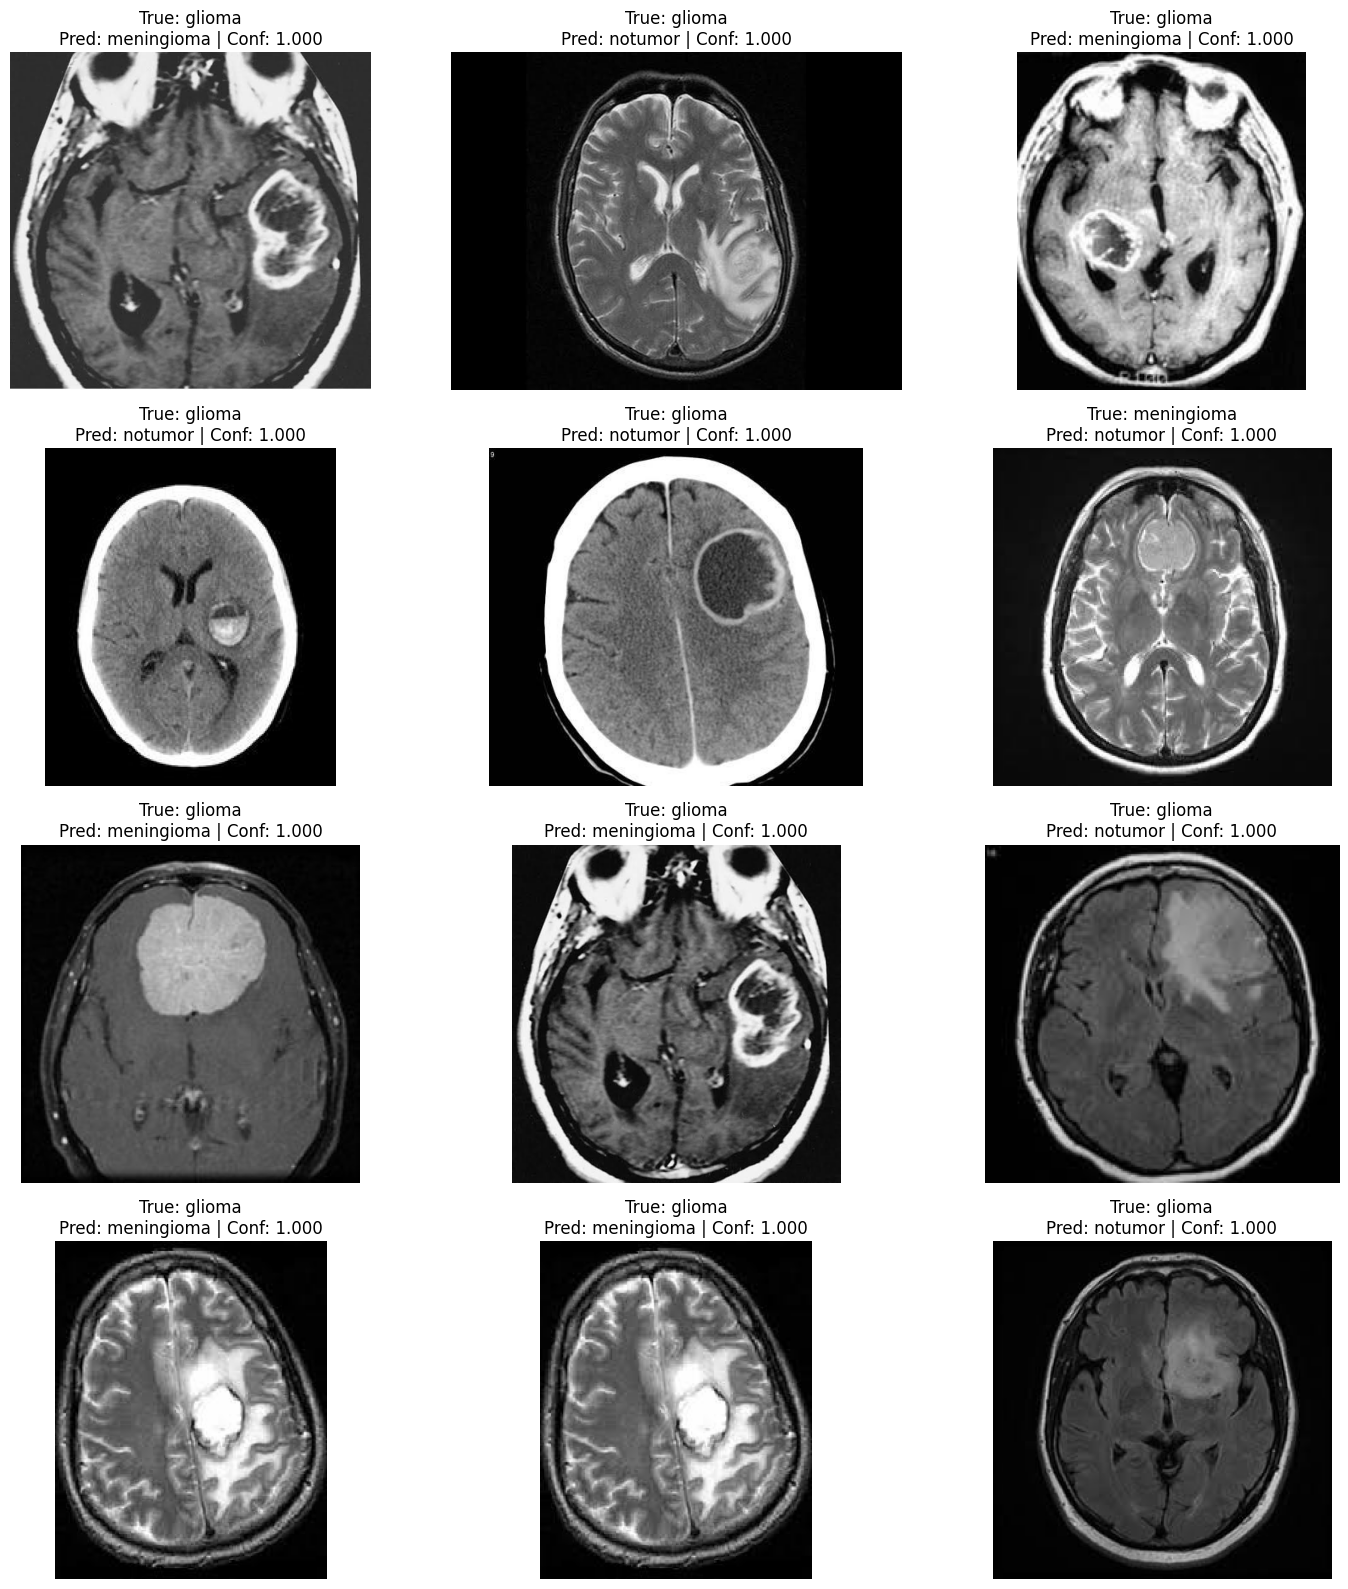

In [10]:
def show_misclassified_images(dataframe, n=12):
    selected = dataframe.head(n)
    if selected.empty:
        print("No misclassified images found.")
        return

    rows = int(np.ceil(len(selected) / 3))
    plt.figure(figsize=(15, rows * 4))

    for plot_idx, (_, row) in enumerate(selected.iterrows(), start=1):
        image = Image.open(row["file_path"]).convert("RGB")
        plt.subplot(rows, 3, plot_idx)
        plt.imshow(image)
        plt.title(
            f"True: {row['true_class']}\n"
            f"Pred: {row['predicted_class']} | "
            f"Conf: {row['confidence']:.3f}"
        )
        plt.axis("off")

    plt.tight_layout()
    plt.savefig(RESULTS_DIR / "high_confidence_mistakes.png", dpi=300)
    plt.show()

show_misclassified_images(errors_df, n=12)

## Cell 11 — Compare confidence on correct and incorrect predictions

Mean confidence — correct: 0.9780126214027405
Mean confidence — incorrect: 0.8206062912940979


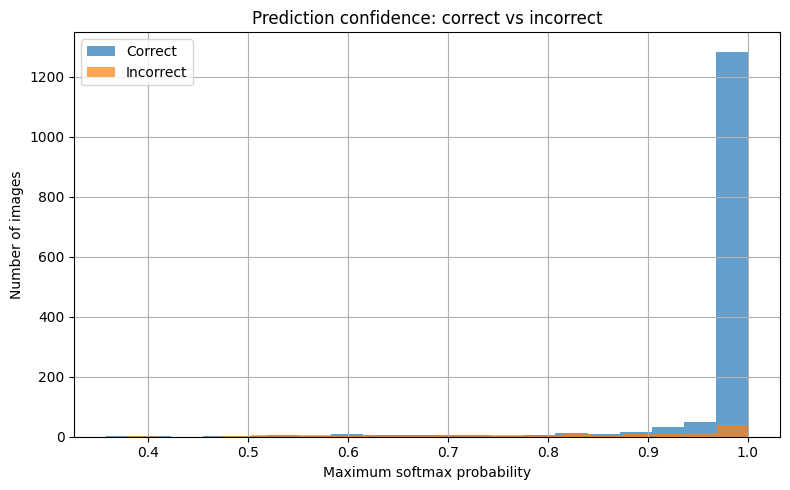

In [11]:
correct_conf = confidence[correct]
incorrect_conf = confidence[~correct]

print("Mean confidence — correct:", float(correct_conf.mean()) if len(correct_conf) else np.nan)
print("Mean confidence — incorrect:", float(incorrect_conf.mean()) if len(incorrect_conf) else np.nan)

plt.figure(figsize=(8, 5))
plt.hist(correct_conf, bins=20, alpha=0.7, label="Correct")
plt.hist(incorrect_conf, bins=20, alpha=0.7, label="Incorrect")
plt.xlabel("Maximum softmax probability")
plt.ylabel("Number of images")
plt.title("Prediction confidence: correct vs incorrect")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "confidence_distribution.png", dpi=300)
plt.show()

## Cell 12 — Reliability diagram and Expected Calibration Error

A model can be accurate but overconfident. This reliability diagram compares average confidence with observed accuracy across confidence bins.

The Expected Calibration Error (ECE) below is a simple bin-based summary. It depends on the number of bins and should be treated as a diagnostic, not a definitive measure.

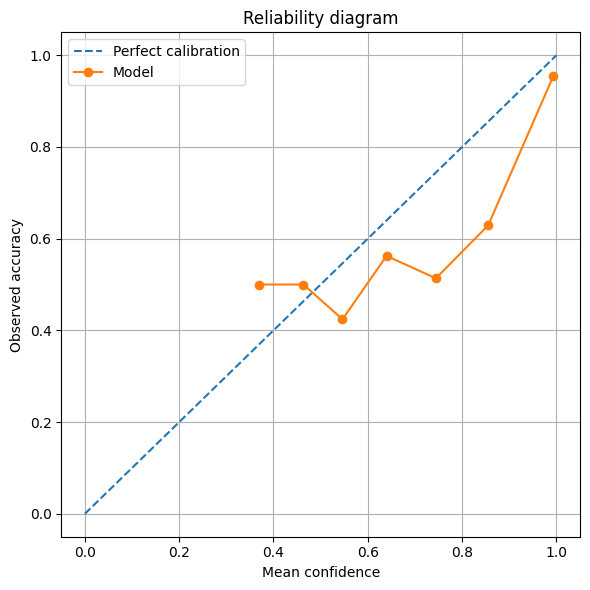

Expected Calibration Error (ECE, 10 bins): 0.0528


In [12]:
n_bins = 10
prob_true, prob_pred = calibration_curve(
    correct.astype(int),
    confidence,
    n_bins=n_bins,
    strategy="uniform"
)

plt.figure(figsize=(6, 6))
plt.plot([0, 1], [0, 1], linestyle="--", label="Perfect calibration")
plt.plot(prob_pred, prob_true, marker="o", label="Model")
plt.xlabel("Mean confidence")
plt.ylabel("Observed accuracy")
plt.title("Reliability diagram")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "reliability_diagram.png", dpi=300)
plt.show()

bin_edges = np.linspace(0, 1, n_bins + 1)
ece = 0.0

for lower, upper in zip(bin_edges[:-1], bin_edges[1:]):
    in_bin = (confidence >= lower) & (confidence < upper)
    if in_bin.any():
        bin_accuracy = correct[in_bin].mean()
        bin_confidence = confidence[in_bin].mean()
        ece += in_bin.mean() * abs(bin_accuracy - bin_confidence)

print(f"Expected Calibration Error (ECE, {n_bins} bins): {ece:.4f}")

## Cell 13 — Extract simple image properties

This cell calculates image width, height, aspect ratio, channel means and standard deviations, brightness, and border brightness from the original test files.

These are descriptive image properties. If they differ between correct and incorrect predictions, that suggests a possible association worth investigating. It does **not** prove that the CNN uses those properties.

In [13]:
def extract_image_features(image_path):
    image = Image.open(image_path).convert("RGB")
    arr = np.asarray(image, dtype=np.float32)

    h, w = arr.shape[:2]
    gray = arr.mean(axis=2)

    border = np.concatenate([
        gray[0, :], gray[-1, :],
        gray[:, 0], gray[:, -1]
    ])

    return {
        "width": w,
        "height": h,
        "aspect_ratio": w / h if h else np.nan,
        "red_mean": arr[:, :, 0].mean(),
        "green_mean": arr[:, :, 1].mean(),
        "blue_mean": arr[:, :, 2].mean(),
        "red_std": arr[:, :, 0].std(),
        "green_std": arr[:, :, 1].std(),
        "blue_std": arr[:, :, 2].std(),
        "brightness_mean": gray.mean(),
        "brightness_std": gray.std(),
        "border_brightness": border.mean()
    }

feature_rows = []
for path in test_file_paths:
    feature_rows.append(extract_image_features(path))

image_features_df = pd.DataFrame(feature_rows)
analysis_df = pd.concat(
    [prediction_df.reset_index(drop=True),
     image_features_df.reset_index(drop=True)],
    axis=1
)

analysis_df.to_csv(RESULTS_DIR / "test_image_error_features.csv", index=False)
display(analysis_df.head())

,file_path,true_label_id,predicted_label_id,true_class,predicted_class,confidence,correct,error_type,width,height,aspect_ratio,red_mean,green_mean,blue_mean,red_std,green_std,blue_std,brightness_mean,brightness_std,border_brightness
0,E:\SEM5\ERA\ERA_Project\Brain_Tumor\data\Testi...,0,3,glioma,pituitary,0.902704,False,misclassified,354,442,0.800905,66.030319,66.030319,66.030319,60.054981,60.054981,60.054981,66.030319,60.054981,0.000000
1,E:\SEM5\ERA\ERA_Project\Brain_Tumor\data\Testi...,0,0,glioma,glioma,1.000000,True,correct,512,512,1.000000,29.126751,29.126751,29.126751,36.335487,36.335487,36.335487,29.126751,36.335487,0.000000
2,E:\SEM5\ERA\ERA_Project\Brain_Tumor\data\Testi...,0,0,glioma,glioma,1.000000,True,correct,512,512,1.000000,26.024830,26.024830,26.024830,31.728493,31.728493,31.728493,26.024830,31.728493,0.003906
3,E:\SEM5\ERA\ERA_Project\Brain_Tumor\data\Testi...,0,3,glioma,pituitary,0.880811,False,misclassified,512,512,1.000000,58.577236,58.577236,58.577236,47.680870,47.680870,47.680870,58.577236,47.680870,2.596680
4,E:\SEM5\ERA\ERA_Project\Brain_Tumor\data\Testi...,0,0,glioma,glioma,0.910698,True,correct,339,406,0.834975,58.226303,58.226303,58.226303,36.441254,36.441254,36.441254,58.226303,36.441254,5.710067


## Cell 14 — Compare image properties for correct and incorrect predictions

width                         height                     \
               mean         std median        mean         std median   
correct                                                                 
False    434.078014  121.880039  512.0  449.070922  122.205076  512.0   
True     435.160384  130.738234  512.0  437.068540  125.646234  512.0   

        aspect_ratio                    red_mean  ...   blue_std  \
                mean       std median       mean  ...     median   
correct                                           ...              
False       0.968914  0.108723    1.0  54.861023  ...  47.939137   
True        0.996560  0.126964    1.0  49.358482  ...  44.332710   

        brightness_mean                       brightness_std             \
                   mean        std     median           mean        std   
correct                                                                   
False         54.861023  22.220545  48.430401      51.772007  11.768141   
True          49.367237  18.568598  46.189320      48.241207  13.273695   

                   border_brightness                       
            median              mean        std    median  
correct                                                    
False    47.939137         13.730282  33.800568  1.748047  
True     44.332710          9.583127  29.419083  1.638672  

[2 rows x 36 columns]

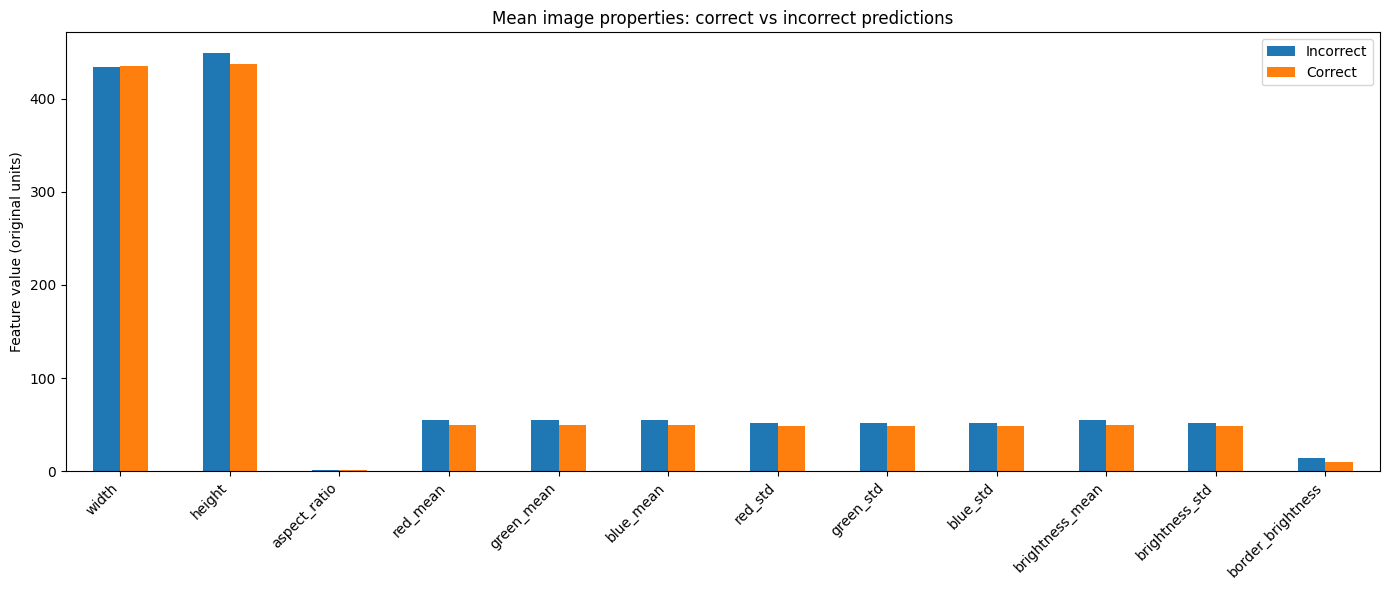

In [14]:
feature_columns = [
    "width", "height", "aspect_ratio",
    "red_mean", "green_mean", "blue_mean",
    "red_std", "green_std", "blue_std",
    "brightness_mean", "brightness_std",
    "border_brightness"
]

group_summary = analysis_df.groupby("correct")[feature_columns].agg(["mean", "std", "median"])
display(group_summary)

group_summary.to_csv(RESULTS_DIR / "correct_vs_incorrect_image_features.csv")

means = analysis_df.groupby("correct")[feature_columns].mean().T
means.columns = ["Incorrect", "Correct"] if list(means.columns) == [False, True] else means.columns

means.plot(kind="bar", figsize=(14, 6))
plt.title("Mean image properties: correct vs incorrect predictions")
plt.ylabel("Feature value (original units)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "image_feature_comparison.png", dpi=300)
plt.show()

## Cell 15 — Class-wise error summary

In [15]:
class_error_summary = (
    analysis_df.groupby("true_class")
    .agg(
        total_images=("correct", "size"),
        correct=("correct", "sum"),
        mean_confidence=("confidence", "mean")
    )
    .reset_index()
)

class_error_summary["incorrect"] = (
    class_error_summary["total_images"] - class_error_summary["correct"]
)
class_error_summary["error_rate"] = (
    class_error_summary["incorrect"] / class_error_summary["total_images"]
)

display(class_error_summary)
class_error_summary.to_csv(RESULTS_DIR / "class_error_summary.csv", index=False)

,true_class,total_images,correct,mean_confidence,incorrect,error_rate
0,glioma,400,312,0.942879,88,0.2200
1,meningioma,400,351,0.920012,49,0.1225
2,notumor,400,399,0.997360,1,0.0025
3,pituitary,400,397,0.996314,3,0.0075


## Cell 16 — Save a compact diagnostic summary

In [16]:
summary = {
    "test_accuracy": float(accuracy_score(y_true, y_pred)),
    "macro_precision": float(precision_score(y_true, y_pred, average="macro", zero_division=0)),
    "macro_recall": float(recall_score(y_true, y_pred, average="macro", zero_division=0)),
    "macro_f1": float(f1_score(y_true, y_pred, average="macro", zero_division=0)),
    "mean_confidence_all": float(confidence.mean()),
    "mean_confidence_correct": float(correct_conf.mean()) if len(correct_conf) else None,
    "mean_confidence_incorrect": float(incorrect_conf.mean()) if len(incorrect_conf) else None,
    "ece_10_bins": float(ece),
    "number_of_test_images": int(len(y_true)),
    "number_misclassified": int((~correct).sum()),
    "class_names": CLASS_NAMES
}

with open(RESULTS_DIR / "notebook_03_diagnostic_summary.json", "w") as f:
    json.dump(summary, f, indent=4)

print(json.dumps(summary, indent=4))
print("\nResults saved to:", RESULTS_DIR)

{
    "test_accuracy": 0.911875,
    "macro_precision": 0.9134185188987599,
    "macro_recall": 0.9118750000000001,
    "macro_f1": 0.910020383498447,
    "mean_confidence_all": 0.9641411304473877,
    "mean_confidence_correct": 0.9780126214027405,
    "mean_confidence_incorrect": 0.8206062912940979,
    "ece_10_bins": 0.05277641538530591,
    "number_of_test_images": 1600,
    "number_misclassified": 141,
    "class_names": [
        "glioma",
        "meningioma",
        "notumor",
        "pituitary"
    ]
}

Results saved to: e:\SEM5\ERA\ERA_Project\Brain_Tumor\outputs\notebook_03\results


## Interpretation guide

Use the results to answer these questions:

1. **Generalization gap:** Is validation accuracy much higher than test accuracy? In the current baseline, it is (approximately 99.9% vs 91.19%). This may reflect a difference in the validation and test image distributions, split characteristics, or other dataset issues. It does not identify the cause by itself.
2. **Class-specific errors:** Glioma recall was 0.78 in Notebook 02. Inspect the glioma false negatives and the classes they were predicted as.
3. **High-confidence errors:** Inspect `high_confidence_mistakes.png` and `misclassified_images.csv`. Look for ambiguous images, label inconsistencies, unusual borders, text, markers, or acquisition differences.
4. **Image-property associations:** Compare correct and incorrect image-property summaries. Differences are clues only; they do not establish causal shortcut learning.
5. **Calibration:** If the reliability curve lies below the diagonal, the model is overconfident in those confidence ranges.
